# Fragment Processing

This notebook covers the first steps of the GATAC preprocessing pipeline:

1. **Convert** TSV.GZ fragments to Parquet format
2. **Fragment size distribution**
3. **Quality metrics**
4. **Build tile matrix**
5. **Feature selection**
6. **Save**

Corresponding CLI commands: `gatac convert`, `gatac filter`, `gatac `

## Setup

Download the PBMC 5k ATAC-seq dataset from 10x Genomics if you haven't already:

In [1]:
%%bash
[ -f data/pbmc_fragments.tsv.gz ] || wget -O data/pbmc_fragments.tsv.gz https://cf.10xgenomics.com/samples/cell-atac/1.2.0/atac_pbmc_5k_nextgem/atac_pbmc_5k_nextgem_fragments.tsv.gz
[ -f data/gencode.v44.primary_assembly.annotation.gtf.gz ] || wget -O data/gencode.v44.primary_assembly.annotation.gtf.gz http://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.primary_assembly.annotation.gtf.gz

In [2]:
import gatac as ga
import matplotlib.pyplot as plt
import time
import numpy as np

print(f"GATAC version: {ga.__version__}")


GATAC version: 0.1.0


## 1. Convert TSV.GZ to Parquet

GATAC uses **Parquet** as its internal fragment format.  Parquet stores data
in row groups that can be read independently, enabling GPU-streaming over
files larger than available VRAM.

In [3]:
FRAGMENTS_TSV = "data/pbmc_fragments.tsv.gz"

t0 = time.perf_counter()
parquet_path = ga.pp.make_parquet(FRAGMENTS_TSV,barcode_prefix="sample1")
print(f"Converted in {time.perf_counter() - t0:.1f}s → {parquet_path}")

15:18:57 - gatac.pp.convert - INFO - Converting pbmc_fragments.tsv.gz to Parquet


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

15:19:13 - gatac.pp.convert - INFO - Created pbmc_fragments.parquet


Converted in 15.9s → data/pbmc_fragments.parquet


The equivalent cli command is:

```bash
gatac convert data/pbmc_fragments.tsv.gz --barcode-prefix sample1
```

By default, this saves the Parquet file to `data/pbmc_fragments.parquet`. The `--barcode-prefix` option is useful when processing multiple independent samples to prevent barcode collisions.

## 2. Fragment size distribution

ATAC-seq fragment sizes show a characteristic nucleosomal ladder pattern:
sub-nucleosomal (<150 bp), mono-nucleosomal (~200 bp), di-nucleosomal (~400 bp).

<Axes: title={'center': 'Fragment size distribution — PBMC 5k'}, xlabel='Fragment size (bp)', ylabel='Count'>

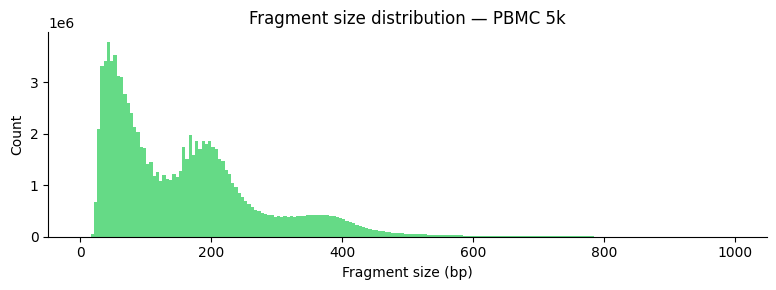

In [4]:
ga.pl.fragment_size_distribution(parquet_path, title="Fragment size distribution — PBMC 5k")

## 3. Quality metrics

In [5]:
GTF = "data/gencode.v44.primary_assembly.annotation.gtf.gz"

tss_df = ga.pp.load_tss_from_gtf(GTF)

t0 = time.perf_counter()
metrics = ga.pp.compute_metrics(
    parquet_path,
    tss_df=tss_df,
    window_size=2000,
    smooth_window=11,
    min_unique_frags=500,
    exclude_chroms=["chrM", "M"],
    row_groups_per_batch=64,
)
print(f"Computed metrics for {len(metrics):,} barcodes in {time.perf_counter() - t0:.1f}s")
metrics_pd = metrics.to_pandas()


15:19:16 - gatac.pp.metrics - INFO - Loading TSS from data/gencode.v44.primary_assembly.annotation.gtf.gz (Polars)
15:19:18 - gatac.pp.metrics - INFO - Loaded 219,362 unique TSSs (Polars)
15:19:18 - gatac.pp.metrics - INFO - Computing metrics (streaming mode, row_groups_per_batch=64)
15:19:18 - gatac.pp.metrics - INFO - Aggregating QC metrics from 101 row groups in batches of 64...
15:19:20 - gatac.pp.metrics - INFO - Found 6,604 cells with >= 500 unique fragments
15:19:20 - gatac.pp.metrics - INFO - Processing 101 row groups in batches of 64...
15:19:22 - gatac.pp.metrics - INFO -   Processed row groups 101/101
15:19:22 - gatac.pp.metrics - INFO - Completed TSSe computation


Computed metrics for 6,604 barcodes in 3.8s


The equivalent cli command would be:
```bash
gatac metrics data/pbmc_fragments.parquet \
    -g data/gencode.v44.primary_assembly.annotation.gtf.gz
```
Saving metrics to `data/pbmc_fragments_metrics.csv` by default.

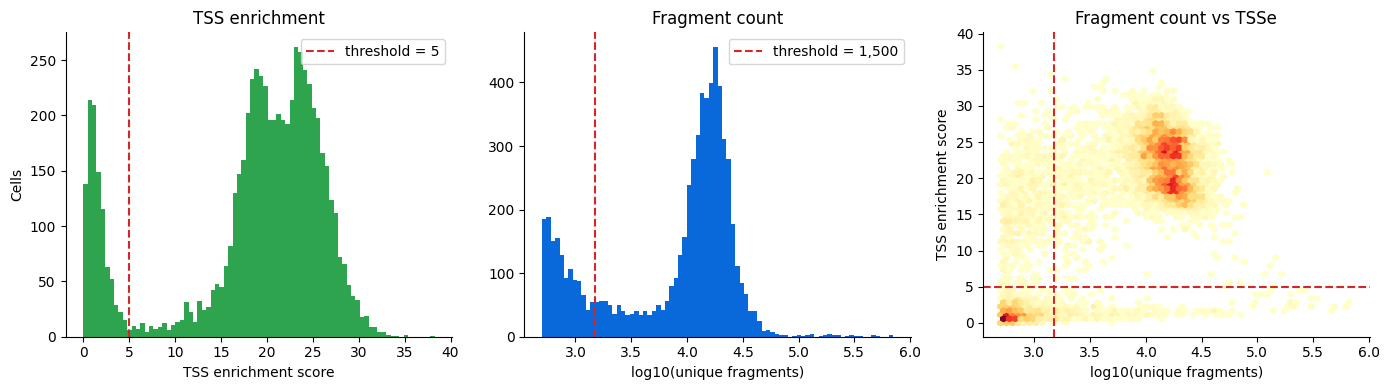

In [6]:
ga.pl.qc_metrics(metrics, tsse_threshold=5, n_unique_threshold=1500)

## 4. Filter QC & Build tile matrix

We chose to retain the fragment file containing all cell barcodes, subsequently filtering out low-quality cells while binning the genome into 500 bp tiles. Unique fragment insertions per cell were then quantified using the SnapATAC2-compatible `"unique"` counting strategy.

In [7]:
t0 = time.perf_counter()
adata = ga.pp.make_tile_matrix(
    parquet_path,
    chrom_sizes="hg38",
    metrics=metrics,
    filter_query="(n_unique >= 1500) & (tsse_score >= 5)",
    tile_size=500,
    exclude_chroms=["chrM", "chrY"],
    count_strategy="unique",
)
print(f"Tile matrix built in {time.perf_counter() - t0:.1f}s")
print(adata)


15:19:36 - gatac.pp.tile - INFO - Processing pbmc_fragments.parquet
15:19:56 - gatac.pp.tile - INFO - Created pbmc_fragments_tile_matrix.h5ad: 5,001 cells × 6,062,095 tiles (20.3s)


Tile matrix built in 20.4s
AnnData object with n_obs × n_vars = 5001 × 6062095
    obs: 'barcode', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction'
    var: 'chrom', 'start', 'end'


The equivalent CLI command is:

```bash
gatac tile data/pbmc_fragments.parquet -g hg38 \
    --metrics data/pbmc_fragments_metrics.csv \
    --filter "(n_unique >= 1500) & (tsse_score >= 5)"
```

By default, the tile matrix will be saved to `data/pbmc_fragments_tile_matrix.h5ad`.

If you prefer to filter the parquet file before running the tiling process, use the following commands:

```bash
gatac filter data/pbmc_fragments.parquet \
    --metrics data/pbmc_fragments_metrics.csv \
    --filter "(n_unique >= 1500) & (tsse_score >= 5)"
gatac tile data/pbmc_fragments_filtered.parquet
```

In [8]:
# Summary stats
print(f"Cells:    {adata.n_obs:,}")
print(f"Tiles:    {adata.n_vars:,}")
print(f"Density:  {adata.X.nnz / (adata.n_obs * adata.n_vars) * 100:.2f}%")

Cells:    5,001
Tiles:    6,062,095
Density:  0.29%


## 5. Feature selection

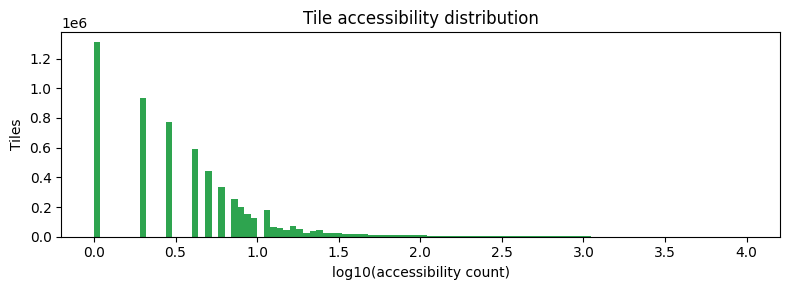

In [9]:
feature_counts = np.asarray(adata.X.sum(axis=0)).flatten()

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.log10(feature_counts + 1), bins=100, color="#2ea44f", edgecolor="none")
ax.set_xlabel("log10(accessibility count)")
ax.set_ylabel("Tiles")
ax.set_title("Tile accessibility distribution")
plt.tight_layout()
plt.show()

`select_features` keeps the top `n_features` most accessible tiles after
removing very rare (<0.5th percentile) and ubiquitously open (>99.5th
percentile) features — following the ArchR strategy.

In [10]:
t0 = time.perf_counter()
ga.pp.select_features(
    adata,
    n_features=500_000,
)
print(f"Feature selection in {time.perf_counter() - t0:.1f}s")
 
n_selected = adata.var["selected"].sum()
print(f"Selected {n_selected:,} / {adata.n_vars:,} features")

15:19:59 - gatac.pp.features - INFO - Selecting features from 6,062,095 total
15:19:59 - gatac.pp.features - INFO - Detected count matrix - using quantile-filtered selection
15:20:00 - gatac.pp.features - INFO - Selected 500,000 features


Feature selection in 0.7s
Selected 500,000 / 6,062,095 features


The equivalent cli command would be:
```bash
gatac features data/pbmc_fragments_tile_matrix.h5ad
```

Saving to `data/pbmc_fragments_tile_matrix_selected.h5ad` by default. 

Note that this function accept a list of tile matrices (if processing multiple samples). The output filtered tile matrices can be combined with:

```bash
gatac features sample*.h5ad
gatac combine sample*tile_matrix.h5ad -o combined.h5ad
```

In that case, make sure to have used `barcode-prefix` in the previous steps to prevent barcode collision.

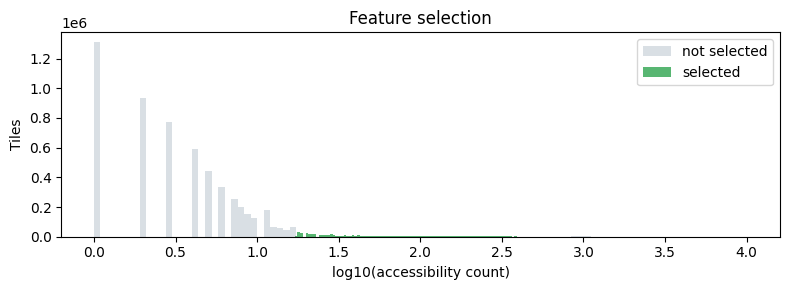

In [11]:
# Highlight selected features
fig, ax = plt.subplots(figsize=(8, 3))

is_selected = adata.var["selected"].values
counts = adata.var["accessibility_count"].values

ax.hist(np.log10(counts[~is_selected] + 1), bins=100,
        color="#d0d7de", edgecolor="none", label="not selected", alpha=0.8)
ax.hist(np.log10(counts[is_selected] + 1), bins=100,
        color="#2ea44f", edgecolor="none", label="selected", alpha=0.8)
ax.set_xlabel("log10(accessibility count)")
ax.set_ylabel("Tiles")
ax.set_title("Feature selection")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Save

In [12]:
adata.write_h5ad("data/pbmc_tile.h5ad")
print("Saved → data/pbmc_tile.h5ad")

Saved → data/pbmc_tile.h5ad


## Next steps

- [02 – Spectral embedding](02_embedding_peak_calling.ipynb): dimensionality reduction and clustering